# Dimensionality Reduction Using Principal Component Analysis (PCA)


Original Dataset Shape: (891, 15)

Explained Variance Ratio (2 components): [0.33960812 0.32520788]
Total Variance Explained: 66.48%


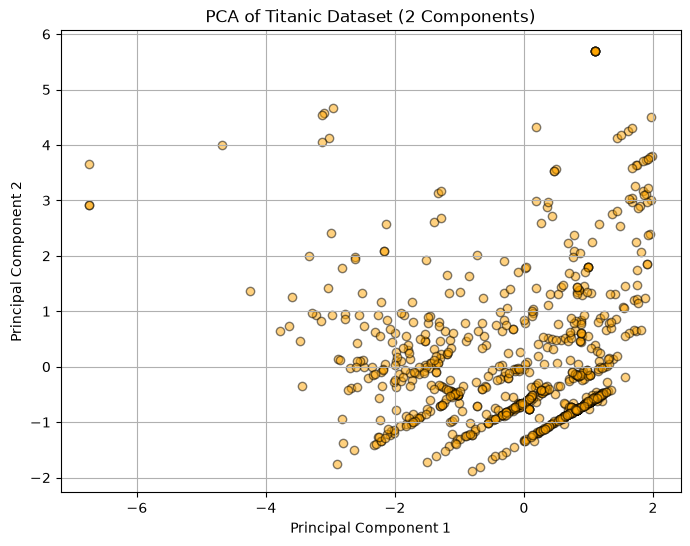

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv('titanic.csv')
print("Original Dataset Shape:", df.shape)

df.columns = df.columns.str.lower()

numerical_features = ['age', 'fare', 'sibsp', 'parch', 'pclass']
df_num = df[numerical_features].copy()

df_num['age'] = df_num['age'].fillna(df_num['age'].median())
df_num['fare'] = df_num['fare'].fillna(df_num['fare'].median())

scaler = StandardScaler()
scaled_data = scaler.fit_transform(df_num)

pca = PCA(n_components=2)
pca_data = pca.fit_transform(scaled_data)

explained_variance = pca.explained_variance_ratio_
print(f"\nExplained Variance Ratio (2 components): {explained_variance}")
print(f"Total Variance Explained: {sum(explained_variance) * 100:.2f}%")

# visualize the first two principal components
plt.figure(figsize=(8, 6))
plt.scatter(pca_data[:, 0], pca_data[:, 1], alpha=0.5, c='orange', edgecolor='k')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('PCA of Titanic Dataset (2 Components)')
plt.grid(True)
plt.show()

## Exercises

Explained Variance Ratio (3 components): [0.33960812 0.32520788 0.14457332]
Total Variance Explained (3 components): 80.94%


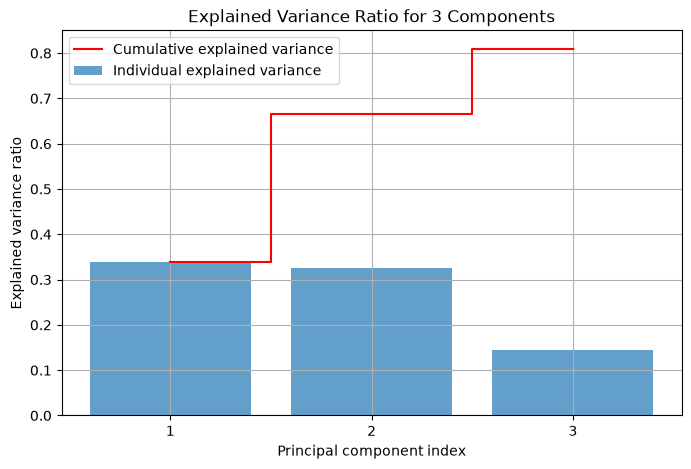

In [2]:
# Exercise 1 & 2: Apply PCA using three principal components and plot explained variance ratio
pca_3 = PCA(n_components=3)
pca_data_3 = pca_3.fit_transform(scaled_data)

explained_variance_3 = pca_3.explained_variance_ratio_
print(f"Explained Variance Ratio (3 components): {explained_variance_3}")
print(f"Total Variance Explained (3 components): {sum(explained_variance_3) * 100:.2f}%")

plt.figure(figsize=(8, 5))
plt.bar(range(1, 4), explained_variance_3, alpha=0.7, align='center', label='Individual explained variance')
plt.step(range(1, 4), np.cumsum(explained_variance_3), where='mid', label='Cumulative explained variance', color='red')
plt.ylabel('Explained variance ratio')
plt.xlabel('Principal component index')
plt.title('Explained Variance Ratio for 3 Components')
plt.xticks([1, 2, 3])
plt.legend(loc='best')
plt.grid(True)
plt.show()

In [3]:
# Exercise 3: Compare the dataset before and after PCA
print("Original Dataset Shape (Selected Features):", df_num.shape)
print("Transformed Dataset Shape (2 Components):", pca_data.shape)

pca_df = pd.DataFrame(data=pca_data, columns=['PC1', 'PC2'])
print("\nFirst 5 rows of original standardized data:\n", df_num.head())
print("\nFirst 5 rows of PCA transformed data (2 Components):\n", pca_df.head())

Original Dataset Shape (Selected Features): (891, 5)
Transformed Dataset Shape (2 Components): (891, 2)

First 5 rows of original standardized data:
     age     fare  sibsp  parch  pclass
0  22.0   7.2500      1      0       3
1  38.0  71.2833      1      0       1
2  26.0   7.9250      0      0       3
3  35.0  53.1000      1      0       1
4  35.0   8.0500      0      0       3

First 5 rows of PCA transformed data (2 Components):
         PC1       PC2
0  1.140660 -0.076520
1 -1.768445  0.133479
2  0.879196 -0.726606
3 -1.458103  0.071555
4  0.561252 -0.943713


PCA Loadings (Feature Contributions):
              PC1       PC2
age    -0.457655 -0.315236
fare   -0.559469  0.367648
sibsp   0.124736  0.615183
parch   0.031850  0.619955
pclass  0.678950 -0.051643


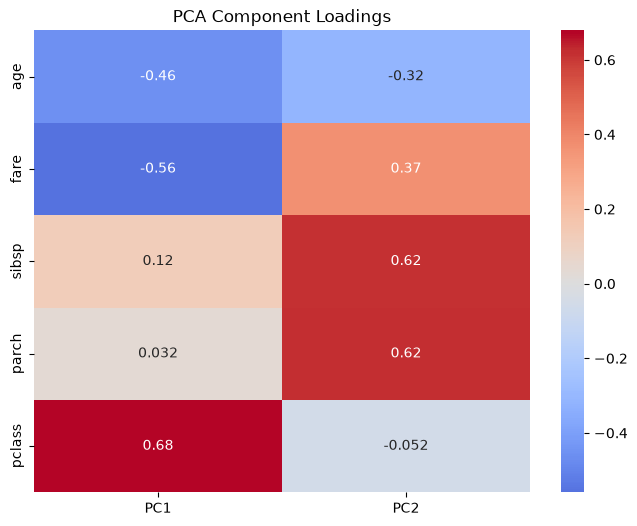


Interpretation:
PC1 is typically influenced strongly by passenger class and fare.
PC2 often captures variance related to family size (sibsp/parch) or age.


In [4]:
# Exercise 4: Interpret the first two principal components
loadings = pd.DataFrame(pca.components_.T, columns=['PC1', 'PC2'], index=numerical_features)
print("PCA Loadings (Feature Contributions):\n", loadings)

plt.figure(figsize=(8, 6))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0)
plt.title('PCA Component Loadings')
plt.show()

print("\nInterpretation:")
print("PC1 is typically influenced strongly by passenger class and fare.")
print("PC2 often captures variance related to family size (sibsp/parch) or age.")